In [6]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# Load dataset
data = load_diabetes()
X, y = data.data, data.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train regression tree
model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


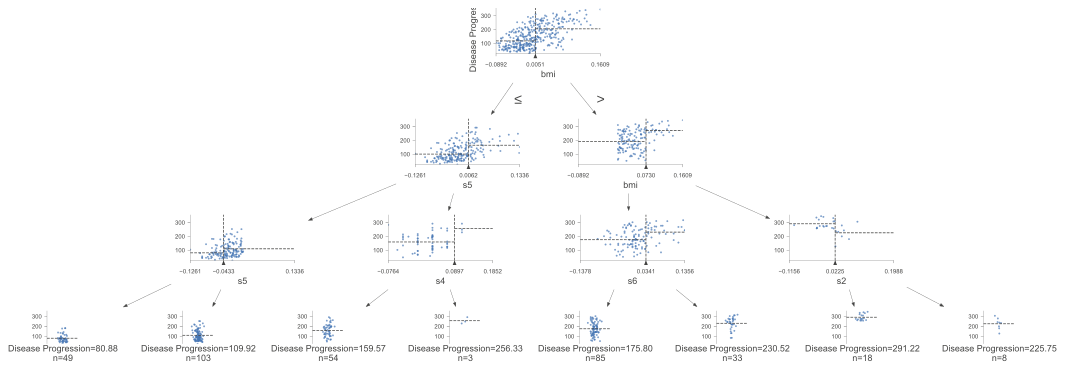

In [7]:
import dtreeviz
import matplotlib.pyplot as plt
viz_model = dtreeviz.model(
    model,
    X_train=X_train,
    y_train=y_train,
    feature_names=data.feature_names,
    target_name="Disease Progression"
)
# viz_model.save("regression_tree.svg")
viz_model.view()


Dataset loaded successfully!
Number of samples: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  

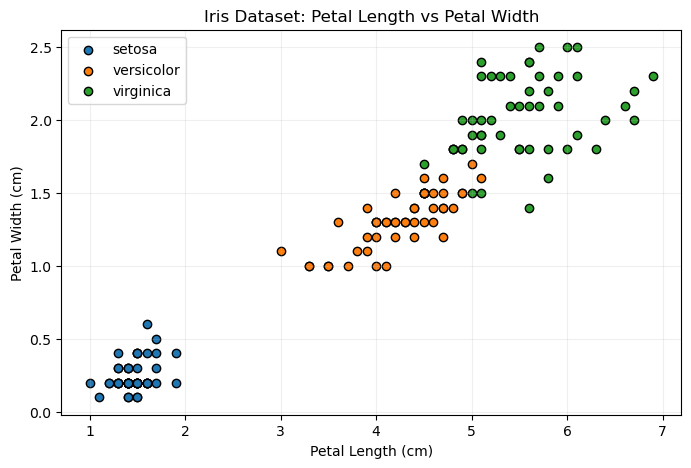


Training samples: 120
Testing samples: 30

Decision Tree model trained successfully!


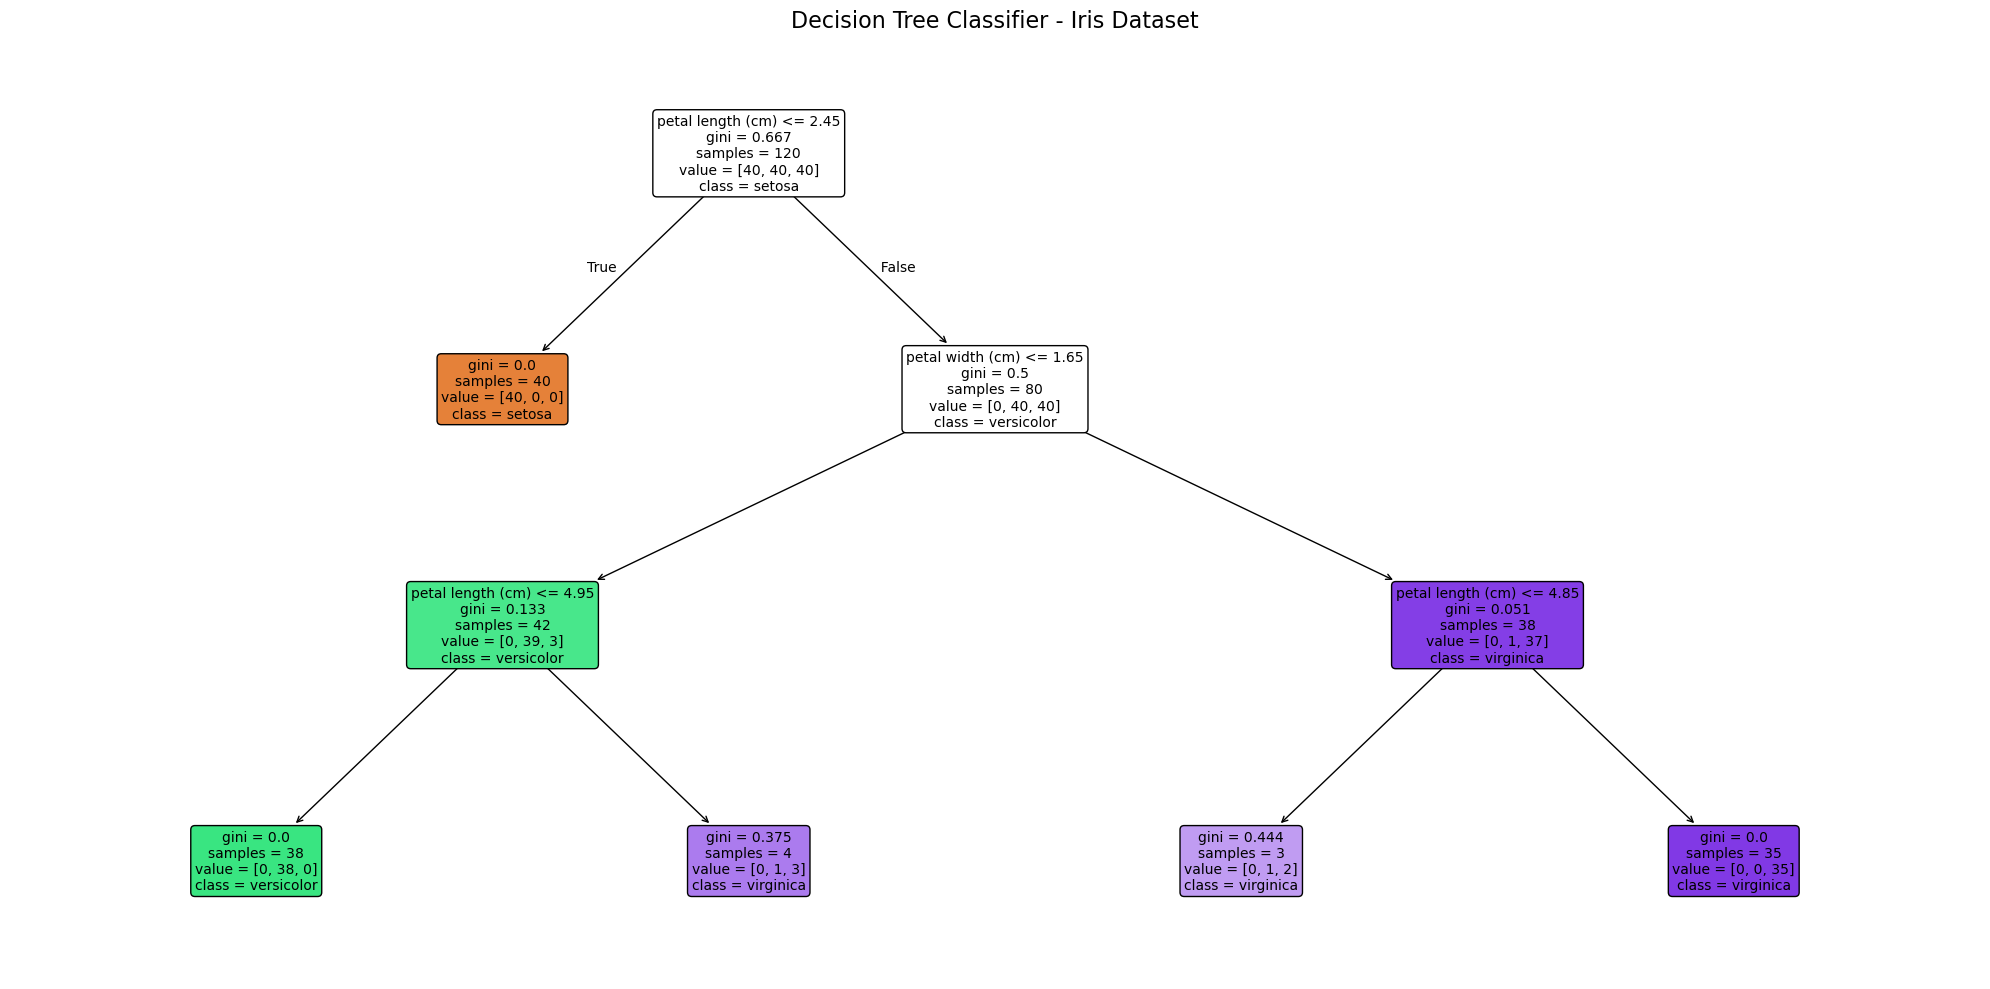


Model Evaluation
----------------
Accuracy: 0.9667
Accuracy Percentage: 96.67%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



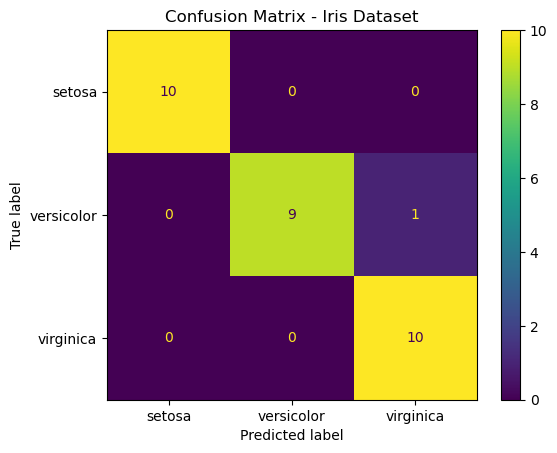


Feature Importance:
          Feature  Importance
petal length (cm)    0.579077
 petal width (cm)    0.420923
sepal length (cm)    0.000000
 sepal width (cm)    0.000000


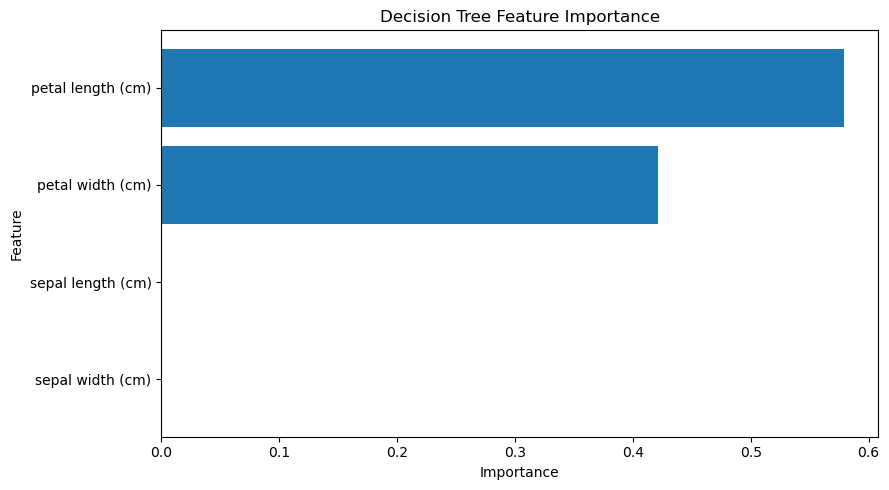

<Figure size 1000x600 with 0 Axes>

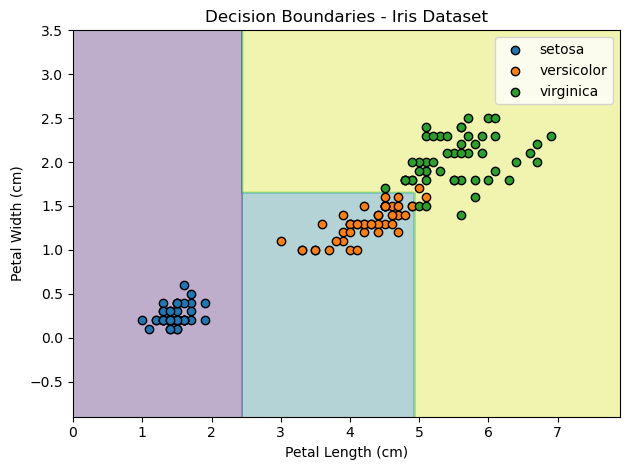


Two-feature model accuracy: 0.9667

New Flower Prediction
---------------------
Input features: [5.1 3.5 1.4 0.2]
Predicted species: setosa

Class Probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


In [9]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import DecisionBoundaryDisplay


# ============================================================
# 2. LOAD THE IRIS DATASET
# ============================================================

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", iris.feature_names)
print("Target classes:", iris.target_names)


# ============================================================
# 3. EXPLORE THE DATASET
# ============================================================

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["species"].value_counts())


# ============================================================
# 4. VISUALIZE THE DATASET
# ============================================================

plt.figure(figsize=(8, 5))

for class_id, class_name in enumerate(iris.target_names):
    plt.scatter(
        X[y == class_id, 2],
        X[y == class_id, 3],
        label=class_name,
        edgecolor="black"
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset: Petal Length vs Petal Width")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# ============================================================
# 5. SPLIT THE DATASET
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 6. CREATE AND TRAIN THE DECISION TREE MODEL
# ============================================================

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully!")


# ============================================================
# 7. VISUALIZE THE DECISION TREE
# ============================================================

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier - Iris Dataset", fontsize=16)
plt.tight_layout()
plt.show()


# ============================================================
# 8. MAKE PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 9. EVALUATE THE MODEL
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Evaluation")
print("----------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()
plt.title("Confusion Matrix - Iris Dataset")
plt.show()


# ============================================================
# 11. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importance:")
print(importance.to_string(index=False))

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# ============================================================
# 12. DECISION BOUNDARY VISUALIZATION
# ============================================================

# Use only petal length and petal width for this visualization.
# This is a separate model from the four-feature model above.

X_2d = iris.data[:, [2, 3]]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_2d = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model_2d.fit(X_train_2d, y_train_2d)

plt.figure(figsize=(10, 6))

DecisionBoundaryDisplay.from_estimator(
    model_2d,
    X_2d,
    response_method="predict",
    xlabel="Petal Length (cm)",
    ylabel="Petal Width (cm)",
    alpha=0.35,
    grid_resolution=200
)

for class_id, class_name in enumerate(iris.target_names):
    plt.scatter(
        X_2d[y == class_id, 0],
        X_2d[y == class_id, 1],
        label=class_name,
        edgecolor="black"
    )

plt.title("Decision Boundaries - Iris Dataset")
plt.legend()
plt.tight_layout()
plt.show()

print("\nTwo-feature model accuracy:",
      f"{accuracy_score(y_test_2d, model_2d.predict(X_test_2d)):.4f}")


# ============================================================
# 13. PREDICT A NEW FLOWER
# ============================================================

# Feature order:
# [sepal length, sepal width, petal length, petal width]

new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = model.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

probabilities = model.predict_proba(new_flower)[0]

print("\nNew Flower Prediction")
print("---------------------")
print("Input features:", new_flower[0])
print("Predicted species:", predicted_species)

print("\nClass Probabilities:")

for class_name, probability in zip(iris.target_names, probabilities):
    print(f"{class_name}: {probability * 100:.2f}%")


Model Accuracy: 96.67%


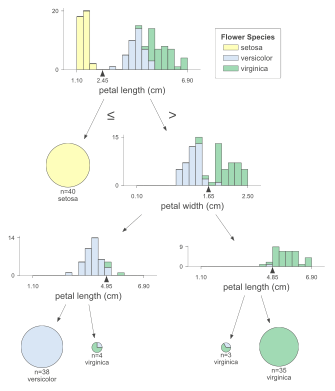

In [12]:

# Import libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import dtreeviz
import matplotlib.pyplot as plt

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Decision Tree
model = DecisionTreeClassifier(
    max_depth=3,
    criterion="gini",
    random_state=42
)

model.fit(X_train, y_train)

# Evaluate model
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Create dtreeviz visualization
viz_model = dtreeviz.model(
    model,
    X_train=X_train,
    y_train=y_train,
    feature_names=iris.feature_names,
    target_name="Flower Species",
    class_names=list(iris.target_names)
)

# Display visualization
viz_model.view()
